In [ ]:
import torch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn as nn

from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Set seed for reproducibility
np.random.seed(42)
CREATE_DATA = True
LOAD_CASE_STUDY = False
LOAD_SIMPLE_DATA = True 

In [4]:

def scale_columns_standard(df, columns_to_scale):
    scaler = StandardScaler()
    df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
    return df

def scale_columns_minmax(df, columns_to_scale):
    scaler = MinMaxScaler()
    df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
    return df

'''def generate_simple_synthetic_data(n_samples=1000, seed=42):
    np.random.seed(seed)

    # 2 input features, randomly sampled
    x1 = np.random.uniform(0, 1, size=n_samples)
    x2 = np.random.uniform(0, 1, size=n_samples)

    # Define true mean and std as simple linear functions
    true_mean = 2 * x1 + 3 * x2       # range: [0, 5]
    true_std = 0.1 + 0.5 * np.abs(x1 - x2)  # range: [0.1, 0.6]

    # Sample y from N(mean, std)
    y = np.random.normal(loc=true_mean, scale=true_std)

    # Return as dataframe + y
    X = pd.DataFrame({'x1': x1, 'x2': x2})
    y = pd.Series(y, name='y')
    
    return X, y, true_mean, true_std'''

def generate_simple_synthetic_data(n_samples=1000, seed=42):
    np.random.seed(seed)

    # Contextual features
    x1 = np.random.uniform(0, 1, size=n_samples)   # e.g., income level normalized [0, 1]
    x2 = np.random.uniform(0, 1, size=n_samples)   # e.g., brand loyalty normalized [0, 1]

    # Price feature (higher price usually decreases demand)
    price = np.random.uniform(1, 10, size=n_samples)  # price between $1 and $10

    # Define true mean (nonlinear relationship)
    true_mean = (5 * x1 + 3 * x2) / (1 + 0.5 * price)  # demand decreases with higher price

    # Define true std (slightly depends on features)
    true_std = 0.2 + 0.3 * np.abs(x1 - x2) + 0.05 * (price / 10)  # more price variation adds more noise

    # Sample y from N(mean, std)
    y = np.random.normal(loc=true_mean, scale=true_std)

    # Package into dataframe
    X = pd.DataFrame({'x1': x1, 'x2': x2, 'price': price})
    y = pd.Series(y, name='y')

    return X, y, true_mean, true_std

'''X, y, true_mean, true_std = generate_simple_synthetic_data()
print(X.head())
print(y.head())'''

def create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"]):

    # Generate client-level data
    client_ids = np.arange(1, num_clients + 1)

    # Income: Should follow a right skewed distribution (log-normal)
    # Adjusting the income distribution to follow a log-normal distribution (right-skewed, long tail)
    mean_income = 10  # Log-normal mean
    sigma_income = 0.6  # Log-normal standard deviation

    # Generate income values (skewed distribution)
    client_incomes = np.random.lognormal(mean=mean_income, sigma=sigma_income, size=num_clients)
    client_incomes = np.interp(client_incomes, (client_incomes.min(), client_incomes.max()), (20000, 200000))

    #client_incomes = np.random.uniform(20000, 100000, size=num_clients)  # Continuous feature: income
    client_spending_categories = np.random.choice(client_categories, size=num_clients)  # Categorical feature

    # Map spending categories to a numerical effect (low = 0.8, mid = 1, high = 1.2)
    category_effects = {"low_spender": 0.8, "mid_spender": 1, "high_spender": 1.2}
    product_base_prices = {1: (10, 30), 2: (15, 50), 3: (5, 25)}

    data = []
    for _ in range(num_transactions):
        client = np.random.choice(client_ids)
        product = np.random.randint(1, num_products + 1)

        # Determine product base price range
        base_price_min, base_price_max = product_base_prices[product]
        mean_price = (base_price_min + base_price_max) / 2

        # Client attributes
        income = client_incomes[client - 1]
        category = client_spending_categories[client - 1]
        category_multiplier = category_effects[category]

        # Price is sampled randomly within the product's base range
        price = np.random.uniform(base_price_min, base_price_max)

        # Amount bought depends on price (inverse relation) and income (higher income buys more)
        base_demand = np.random.uniform(5, 20)  # Base demand per product
        income_factor = (income / 200000)  # Scaled income effect (higher income = more purchases)
        
        '''print("&"*50)
        print("price: ", price)
        print("mean_price: ", mean_price)
        print("price / mean_price: ", price / mean_price)
        print("(price / mean_price)**2: ", (price / mean_price)**2)
        print("(1 / (1 + (price / mean_price)**2)): ", (1 / (1 + (price / mean_price)**2)))
        print("&"*50)'''
        #amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (1 + (price / mean_price)**2))) + np.random.normal(0, 1))
        #amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (price / mean_price)**2)) + np.random.normal(0, 1))

        # Separate deterministic and stochastic parts
        deterministic_part = (base_demand * category_multiplier * income_factor * (1 / (price / mean_price)**2))
        #print("deterministic_part: ", deterministic_part)
        # Stochastic part: noise based on price and income. Each row has a different noise. amount_boughtᵢ ~ Normal(μᵢ, σᵢ²)
        std_dev = 0.5 + 0.1 * (price / mean_price)**2 + 0.1 * (1 - income_factor)
        #print("std_dev: ", std_dev)
        noise = np.random.normal(0, std_dev)
        print("noise: ", noise)
        amount_bought = max(0, (deterministic_part + noise))

        data.append([client, product, price, amount_bought, income, category])

    # Create DataFrame
    df = pd.DataFrame(data, columns=["client_id", "product_id", "offered_price", "amount_bought", "income", "client_category"])
    df["amount_bought"] = df["amount_bought"].round().astype(int)
    df["amount_bought"] = df["amount_bought"].clip(lower=0)  # Ensure no negative values

    df_name_to_save = f"synthetic_dataset_{num_clients}clients_{num_transactions}trans.csv"
    df.to_csv("data/" + df_name_to_save, index=False)
    return df, df_name_to_save

def load_case_study_data():
    data = pd.read_csv('../DistCL_code/data_house_japan/data_clean.csv', index_col=0)
    data.index = pd.to_datetime(data.index)

    y = data['demand']
    X = data.drop(['demand'], axis=1, inplace=False)

    val_ind = X.index[(X.index >= pd.to_datetime('2018-11-01')) & (X.index < pd.to_datetime('2018-12-01'))]
    test_ind = X.index[X.index >= pd.to_datetime('2018-12-01')]

    return X, y, val_ind, test_ind


In [5]:
if CREATE_DATA:
    print("Creating synthetic data...")
    df, df_name = create_synthetic_csv(num_clients=1, num_transactions=10000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"])

Creating synthetic data...
noise:  -0.0857664558500284
noise:  0.8162538376341605
noise:  0.4046519256821877
noise:  -0.31291016016318307
noise:  -0.48238049639283787
noise:  -0.5739180959456124
noise:  -0.7503017580861602
noise:  0.3212548626376159
noise:  0.44281004567485044
noise:  0.19716227295042946
noise:  -0.41619059515367
noise:  0.3010952971761415
noise:  -0.425749862323898
noise:  -1.1425979444955936
noise:  -0.6836909394059341
noise:  -0.5501923430529889
noise:  -0.9638015228604002
noise:  0.18180652779689285
noise:  -0.20277974268964843
noise:  0.3194808419694473
noise:  0.6146320786483982
noise:  0.1894293253170109
noise:  0.5188359438133514
noise:  0.4724036442878351
noise:  0.17139942747213102
noise:  -0.02442021554506476
noise:  1.0116523733549434
noise:  1.4464416309979902
noise:  -0.5508878967961687
noise:  -0.1442182103022446
noise:  -0.2982682364159069
noise:  -0.3341711985298443
noise:  0.35907677889770695
noise:  -0.18824224324612038
noise:  -0.1917672420325413
no

In [6]:
if LOAD_CASE_STUDY:
    print("Loading case study data...")
    X, y, val_ind, test_ind = load_case_study_data()
    display(X.head())

elif LOAD_SIMPLE_DATA:
    X, y, true_mean, true_std = generate_simple_synthetic_data()
    
    scale_columns_minmax(X, ['x1', 'x2'])
    print(X.head())
    print(y.head())
else:
    print("Loading synthetic data...")
    # Load the synthetic dataset
    df = pd.read_csv("data/synthetic_dataset_1clients_10000trans.csv")
    df = df[df['client_id'] == 1]  # Filter for client_id = 1
    display(df.head())
    print("len(df):", len(df))

    df = df[df['product_id'] ==3 ]

    plt.figure(figsize=(4, 4))
    sns.scatterplot(x=df["offered_price"], y=df["amount_bought"], alpha=0.5)
    plt.xlabel("Offered Price")
    plt.ylabel("Amount Bought")
    plt.title("Amount Bought vs Offered Price")
    plt.show()

    target = 'amount_bought'
    #numerical_features = ['offered_price', 'income']
    numerical_features = ['offered_price']
    categorical_features = ['client_category']
    columns_to_use = numerical_features + [target]
    correlation_matrix = df[numerical_features + [target]].corr()
    print(correlation_matrix)

    scale_columns_minmax(df, numerical_features)


         x1        x2     price
0  0.371735  0.182609  3.355351
1  0.950755  0.540740  3.222809
2  0.730954  0.873049  9.156291
3  0.596960  0.731791  3.245916
4  0.152134  0.806411  3.447548
0    1.196791
1    2.651868
2    1.322522
3    1.628576
4    1.674565
Name: y, dtype: float64


In [7]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

model_config = {
    'hidden_layers': 2,
    'hidden_size': 64,
    'drop': 0.2
    }

training_config = {
    'lr': 0.01,
    'wd': 0.0001,
    'batchsize': 64,
    'iters': 500
    }



In [8]:
'''trainer = Trainer(X, y, model_config, training_config)
trainer.create_data_partitions()
print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)
trainer.train()
trainer.test()'''

'trainer = Trainer(X, y, model_config, training_config)\ntrainer.create_data_partitions()\nprint("X_train shape: ", trainer.X_train.shape)\nprint("X_val shape: ", trainer.X_val.shape)\nprint("X_test shape: ", trainer.X_test.shape)\ntrainer.train()\ntrainer.test()'

In [9]:
from utils import Trainer

In [10]:
np.random.seed(42)
torch.manual_seed(1)
if LOAD_CASE_STUDY:
    print("Loading case study data...")
    trainer = Trainer(X, y, model_config, training_config, device=device)
    trainer.set_data_partitions(X_train=X[(~X.index.isin(val_ind)) & (~X.index.isin(test_ind))], y_train=y[(~y.index.isin(val_ind)) & (~y.index.isin(test_ind))], X_val=X[X.index.isin(val_ind)], y_val=y[y.index.isin(val_ind)], X_test=X[X.index.isin(test_ind)], y_test=y[y.index.isin(test_ind)])
elif LOAD_SIMPLE_DATA:
    print("Loading simple synthetic data...")
    trainer = Trainer(X, y, model_config, training_config, device=device)
    trainer.create_data_partitions(val_size=0.2, test_size=0.2, random_state=42)
else:
    print("Loading synthetic data...")
    trainer = Trainer(df[['offered_price', 'income']], df['amount_bought'], model_config=model_config, training_config=training_config, device=device)

    trainer.create_data_partitions(val_size=0.2, test_size=0.2, random_state=42)

print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)

trainer.train()

trainer.test()

Loading simple synthetic data...
X_train shape:  (600, 3)
X_val shape:  (200, 3)
X_test shape:  (200, 3)
Epoch 1/500 - Train Loss: 164958.5635, Val Loss: 2.5376
Epoch 2/500 - Train Loss: 2.4048, Val Loss: 1.3940
Epoch 3/500 - Train Loss: 1.4367, Val Loss: 1.1489
Epoch 4/500 - Train Loss: 1.1597, Val Loss: 0.6836
Epoch 5/500 - Train Loss: 52.2862, Val Loss: 0.8282
Epoch 6/500 - Train Loss: 1.0179, Val Loss: 0.6773
Epoch 7/500 - Train Loss: 0.9054, Val Loss: 0.6903
Epoch 8/500 - Train Loss: 0.8328, Val Loss: 0.5203
Epoch 9/500 - Train Loss: 0.7774, Val Loss: 0.3942
Epoch 10/500 - Train Loss: 0.7182, Val Loss: 0.5462
Epoch 11/500 - Train Loss: 0.7291, Val Loss: 0.4686
Epoch 12/500 - Train Loss: 0.6384, Val Loss: 0.5065
Epoch 13/500 - Train Loss: 0.7289, Val Loss: 0.3907
Epoch 14/500 - Train Loss: 0.6125, Val Loss: 0.4895
Epoch 15/500 - Train Loss: 0.6616, Val Loss: 0.5868
Epoch 16/500 - Train Loss: 0.5785, Val Loss: 0.3227
Epoch 17/500 - Train Loss: 0.5489, Val Loss: 0.3382
Epoch 18/500 -

In [11]:
cons = trainer.constraint_build()
cons.to_csv('constraints_1_50.csv')

In [12]:
cons = pd.read_csv('constraints_1_50.csv', index_col=0)
cons

,intercept,layer,node,node_0,node_1,node_2,node_3,node_4,node_5,node_6,...,node_54,node_55,node_56,node_57,node_58,node_59,node_60,node_61,node_62,node_63
0,-5.466294e-07,0,0,-1.709312e-12,-5.645842e-13,-0.029156,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-5.195949e-01,0,1,-2.213936e-01,-1.078023e+00,-0.148349,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-1.945184e-01,0,2,-6.616550e-01,-3.081619e-01,-0.536000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5.307694e-03,0,3,-3.768307e-05,-6.320571e-05,-0.048014,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-1.090852e-01,0,4,-1.288613e-01,-5.616592e-01,-0.445790,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,-3.965873e-01,2,61,4.097143e-04,-2.598158e-02,-0.020993,1.378172e-18,-0.058063,-0.149786,-4.913100e-41,...,1.196230e-40,2.352840e-40,0.011932,0.359359,0.074226,0.033839,0.030750,-2.354056e-08,-0.159269,5.999200e-41
62,-1.501396e-02,2,62,-1.460236e-01,3.966310e-02,-0.033863,-1.494790e-01,-0.114161,-0.106820,-4.907600e-41,...,-1.597888e-01,-5.905100e-41,-0.090620,-0.030417,-0.008404,-0.122706,-0.098665,-1.068135e-01,0.032674,1.706334e-03
63,-3.591654e-02,2,63,-7.836243e-02,-8.325323e-02,0.061881,-2.219470e-02,-0.002931,0.116596,-1.246576e-12,...,-7.119059e-02,-4.911600e-41,0.046216,-0.036127,-0.000182,-0.045055,-0.079431,4.917300e-41,-0.080210,-5.455904e-17
0,8.925824e-02,3,0,3.152944e-01,3.031349e-01,0.033769,1.754486e-01,0.166655,-0.219412,5.582492e-02,...,-2.343798e-01,5.700016e-02,-0.069820,0.282334,0.040192,0.030357,0.027514,-2.043960e-01,-0.050102,5.790141e-02


In [13]:
mean_pred, sd_pred = trainer.predict(trainer.X_test)
mean_pred = np.squeeze(mean_pred)
sd_pred = np.squeeze(sd_pred)

def compute_nll(y_true, y_pred, y_std):
    """
    Computes Negative Log-Likelihood (NLL) for Gaussian distribution.
    
    Parameters:
    - y_true: True target values (numpy array).
    - y_pred: Predicted mean (numpy array).
    - y_std: Predicted standard deviation (numpy array).
    
    Returns:
    - Scalar NLL value
    """
    var = y_std ** 2  # Convert std deviation to variance
    nll = np.mean((y_true - y_pred) ** 2 / (2 * var) + 0.5 * np.log(2 * np.pi * var))
    return nll



nll = compute_nll(trainer.y_test, mean_pred, sd_pred)
print(f"Negative Log-Likelihood (NLL): {nll:.4f}")


Negative Log-Likelihood (NLL): 1.1338


In [14]:
y_train_tensor = torch.tensor(trainer.y_train.values, dtype=torch.float32).unsqueeze(1)  # shape [N, 1]

baseline_mean = torch.mean(y_train_tensor)
baseline_std = torch.std(y_train_tensor) # + 1e-6

# Repeat the values for every row
baseline_mean_preds = baseline_mean.repeat(y_train_tensor.shape[0], 1)
baseline_std_preds = baseline_std.repeat(y_train_tensor.shape[0], 1)

# Square std to get variance
baseline_var_preds = baseline_std_preds ** 2

criterion = nn.GaussianNLLLoss()
baseline_loss = criterion(baseline_mean_preds, y_train_tensor, baseline_var_preds)

print(f"Baseline Gaussian NLL Loss: {baseline_loss.item():.4f}")

pred_mean, pred_sd = trainer.predict(trainer.X_val, return_tensor=True)     # X_val: torch tensor of shape [N, D]
pred_var = pred_sd ** 2               # square to get variance
y_val_tensor = torch.tensor(trainer.y_val.values, dtype=torch.float32).unsqueeze(1).to(device)
model_loss = criterion(pred_mean, y_val_tensor, pred_var)

print(f"Model Gaussian NLL Loss: {model_loss.item():.4f}")

Baseline Gaussian NLL Loss: 0.3201
Model Gaussian NLL Loss: 0.2325


In [15]:
pred_sd

tensor([[0.7788],
        [0.7666],
        [0.7567],
        [0.7651],
        [0.7720],
        [0.7698],
        [0.7514],
        [0.7892],
        [0.7726],
        [0.7711],
        [0.7472],
        [0.7568],
        [0.7595],
        [0.7683],
        [0.7740],
        [0.7673],
        [0.7734],
        [0.7676],
        [0.7712],
        [0.7675],
        [0.7552],
        [0.7724],
        [0.7858],
        [0.7718],
        [0.7711],
        [0.7543],
        [0.7654],
        [0.7601],
        [0.7760],
        [0.7668],
        [0.7619],
        [0.7682],
        [0.7559],
        [0.7756],
        [0.7732],
        [0.7681],
        [0.7669],
        [0.7735],
        [0.7834],
        [0.7714],
        [0.7956],
        [0.7913],
        [0.7925],
        [0.7727],
        [0.7820],
        [0.7880],
        [0.7789],
        [0.7700],
        [0.7561],
        [0.7764],
        [0.7527],
        [0.7640],
        [0.7746],
        [0.7629],
        [0.7677],
        [0

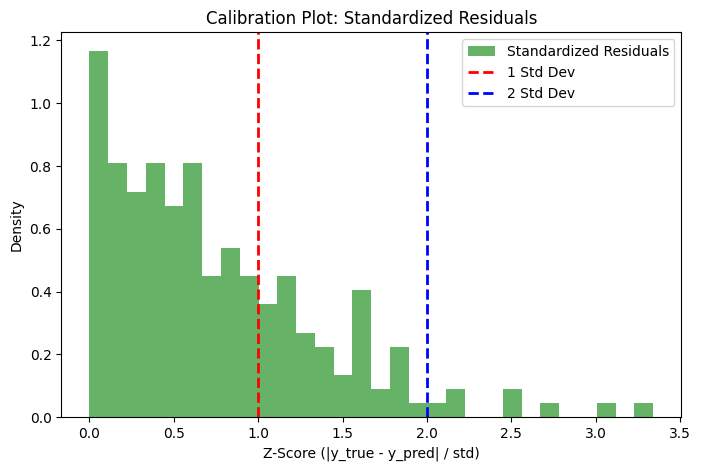

In [16]:
def plot_calibration(y_true, y_pred, y_std):
    """
    Creates a histogram of standardized residuals (Z-scores) to check uncertainty calibration.
    
    Parameters:
    - y_true: True target values (numpy array).
    - y_pred: Predicted mean (numpy array).
    - y_std: Predicted standard deviation (numpy array).
    
    Returns:
    - Calibration plot
    """
    z_scores = np.abs(y_true - y_pred) / y_std  # Standardized residuals

    plt.figure(figsize=(8, 5))
    plt.hist(z_scores, bins=30, density=True, alpha=0.6, color='g', label='Standardized Residuals')

    # Reference lines at 1σ and 2σ
    plt.axvline(1, color='r', linestyle='dashed', linewidth=2, label='1 Std Dev')
    plt.axvline(2, color='b', linestyle='dashed', linewidth=2, label='2 Std Dev')

    plt.xlabel('Z-Score (|y_true - y_pred| / std)')
    plt.ylabel('Density')
    plt.legend()
    plt.title('Calibration Plot: Standardized Residuals')
    plt.show()

plot_calibration(trainer.y_test, mean_pred, sd_pred)
